# Price tier prediction

A multiclass classification problem, aimed for predicting price tier of a work place with respect to its features set,
using simple ways to workwith complete end to end machine learning pipeline for making this sytem work. Dataset details,
walk through with complete roadmap with learning machine learning hands on.

**Real Life usecase**
Model is scoped stricly for academic purpose, But could be used in several ways
+ Working as ranking list engine for automated price prediction through scraped details about workspace
+ Listing strongness of work places with our own listing index
+ commercializing listing and improvement directions for workspace for our index range

Thus model could be integrated for a application for companies to manage there hybrid offices location.
rest core architechture and learning could be expanded for soo many problem scope.

In [1]:
# GLOBAL PARAMETERS

TRAIN_PATH = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/train.csv'
TEST_PATH = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/test.csv'

## Exploratory data analysis

We would explore dataset with univariate approach with both categorical and numerical, 
implementing simple binning and aggregation perspective with dataset we would broadly follow simple rules

Simple univarite exploration
+ Plot univariate unit with single distribution
+ Plot the relation between target value with the feature of interest

In [2]:
# Basic data exploration
import pandas as pd 

df = pd.read_csv(TRAIN_PATH)

# Utility function for targeted relation plot

def relation_ploter(relation, size):
    ''' 
    Makes targeted distribution plot with alligned group df element
    relation_dataframe[grouping_element].groupby('price_tier')
    '''
    # Relation ploting tool
    fig, ax = plt.subplots(
        1, size, figsize=(15,2),
        layout='tight'
    )

    for i, (space_class, group_series) in enumerate(relation.groupby(level=0)):
        price_tier_counts = group_series.droplevel(0)
        price_tier_counts = price_tier_counts.sort_index()

        price_tier_counts.plot(
            kind='bar',
            ax=ax[i],
            color='darkblue',
            edgecolor='black'
        )
        ax[i].set_title(space_class)
        ax[i].set_xlabel("Target Class")
        ax[i].set_ylabel("Count")
        ax[i].tick_params(axis='x', rotation=0) # Keep x-labels upright


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  str    
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  str    
 7   operator_certified            279142 non-null  str    
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  str    
 10  operator_id_verified          279142 non-null  str    
 11  zone                          279746 non-null  str    
 12  borough                       65295 non-null   str    


Distribution of potential categorical | high cardinal feature


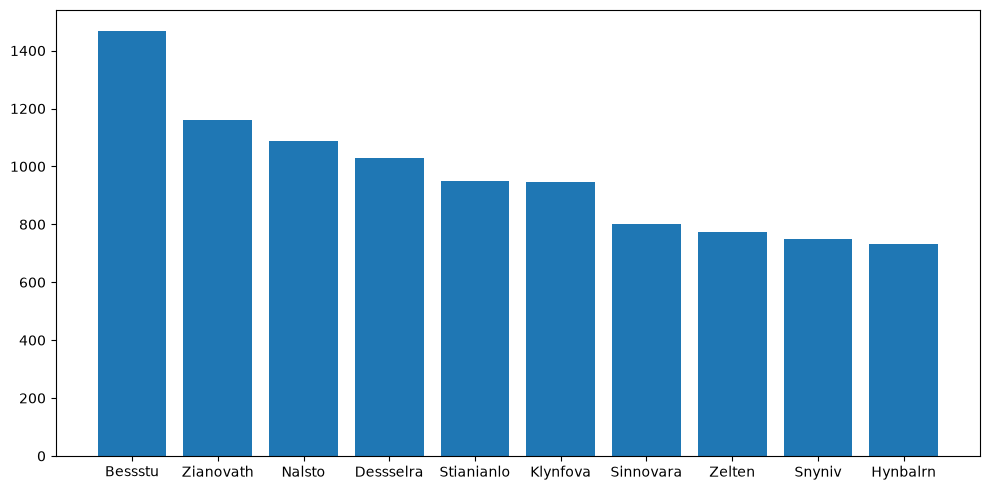

In [3]:
'''
Targeted variable for exploration
operator_ref, operator_class, space_class

Kernel Crash during plot
With 41 thousand reference unique,
we cant direct plot those numbers

Potential dropout with operator_ref
covering with 14 percent on total dataset size

Potential imputation with distribution of these refrences
with other based binning for rest of non-common elements
'''
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

ref_data = df.loc[:, 'operator_ref'].dropna()

# top 10 ranker of referals
rankers = ref_data.value_counts()[:10]
plt.figure(figsize=(10,5))
plt.bar(
    rankers.index, 
    rankers,
    width=0.8
)
plt.tight_layout()
print("Distribution of potential categorical | high cardinal feature")

feature scope : <StringArray>
['independent_operator', 'unverified_operator', 'managed_operator']
Length: 3, dtype: str


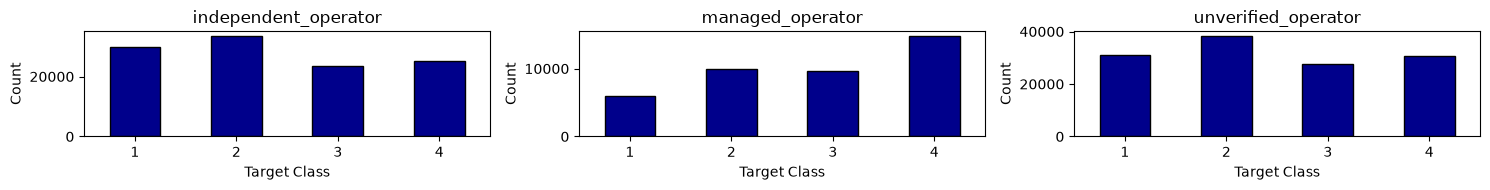

In [4]:
# Target : oprator_class

feature = df['operator_class'].dropna()
scope = feature.unique()
print(f"feature scope : {scope}")

# How is the all three classes are distributed ?
distribution = feature.value_counts()

# what is the relation of operator_class with target feature ?
relation = df.groupby('operator_class')['price_tier'].value_counts().sort_values()

relation_ploter(relation, size=3)

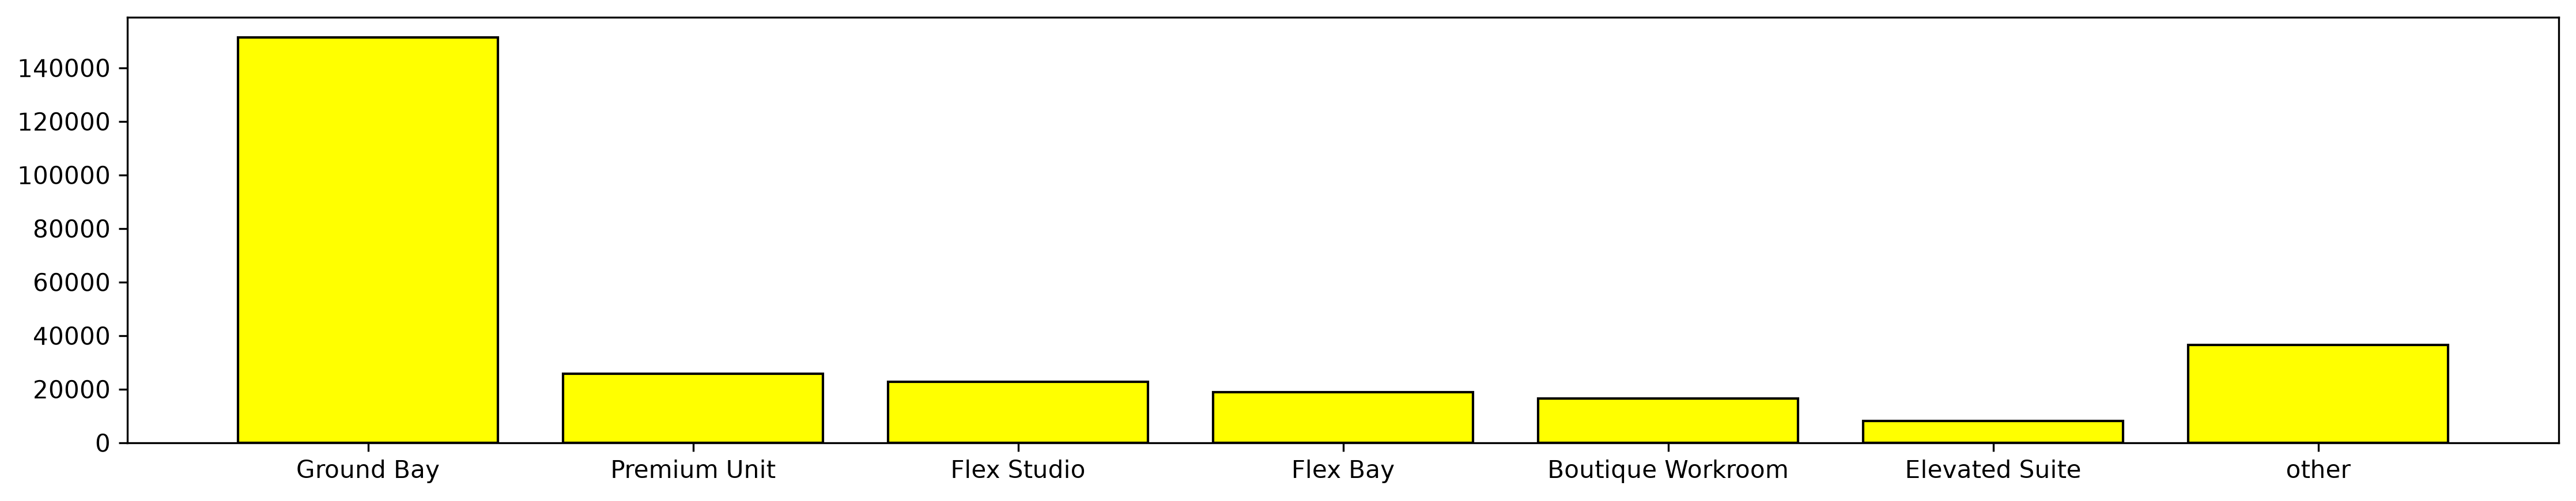

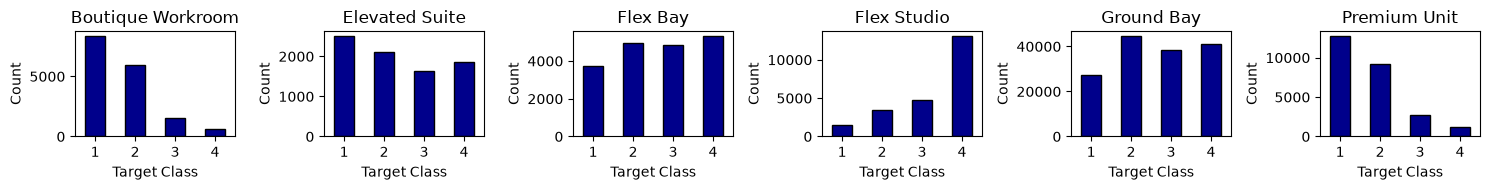

In [5]:
# Exploring space class distribution

feature = df['space_class'].dropna()
#print(f"Looking with distribution of the values with class : {feature.unique()}")

size = 6
# Grouping elements with value counting ranking
values = feature.value_counts(ascending=False)

# top ranker data
rankers = list(values.index[:size])
freq = list(values[:size])

# Leading other bin
other_sum = values[size:].sum()
rankers.append('other')

freq.append(other_sum)
plt.figure(figsize=(15,3), dpi=300)
plt.bar(
    x=rankers,
    height=freq,
    color='yellow',
    edgecolor='black'
)
plt.tight_layout()

# realtion of feature rankers with price tier
space_classing = df[
    df['space_class'].isin(rankers[:-1])
]

space_class_relation = space_classing.groupby(
    'space_class'
)['price_tier'].value_counts()

relation_ploter(space_class_relation, size=size)

<style> font-family:'Verdana';</style>
### <center> Categorical EDA report 📑 </center>

With given set of features, we can see some really nice insights about picked features,
operator_ref contains really big number of elements which makes it non-ideal for seting up with one-hot encoding, dataset contains high variability, along with thousand of features, thus in first place it looked as promising feature to have but now its leaning towards droping

With `operator_class` we assumed to have good directive distribution with the target feature where it contains slight featuring with target features. we would approach for making its onehot encoding through which model might benifit with its certain neiche distribution pattern we see in plot

With space_class distribution plot we can see really strong pattern of followup, features are trending with one perticular class with perticular space class, which is really good for making them with targeted encoding for featuring them into the next plot with OneHot encoding set.

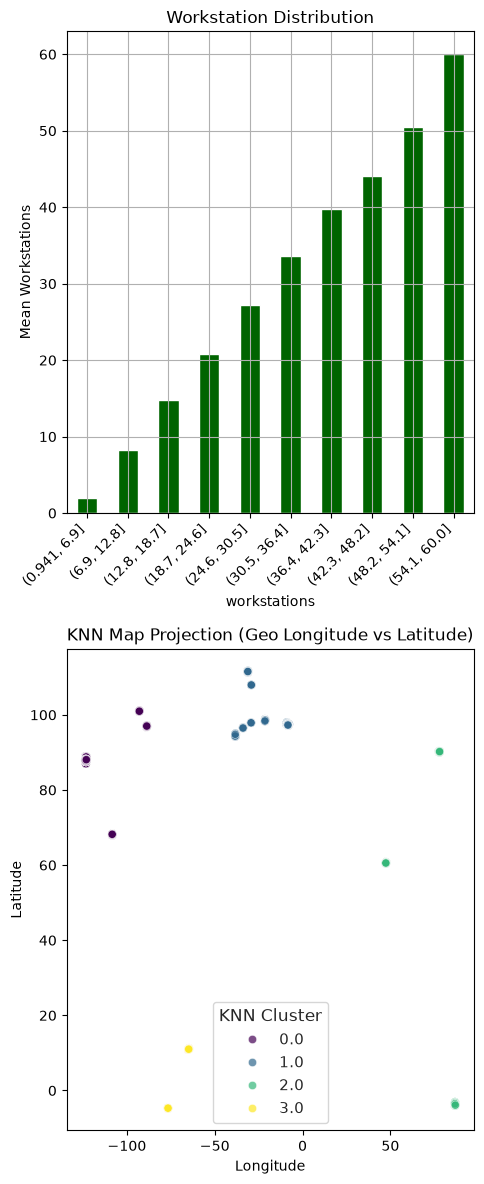

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Imports missing from the user snippet
from sklearn.neighbors import KNeighborsClassifier

# Set layout parameters
total_plots = 2
fig, axs = plt.subplots(total_plots, 1, figsize=(5, 12), layout="tight")
sns.set_theme(style="whitegrid")

# --- Plot 1: Workstation Distribution Bins ---
workstations = df["workstations"].dropna()
workstation_group = pd.cut(workstations, bins=10)

# Calculate means per bin for plotting values correctly
bin_means = workstations.groupby(workstation_group, observed=False).mean()
bin_means.plot(
    kind="bar", color="darkgreen", ax=axs[0], title="Workstation Distribution"
)
axs[0].set_ylabel("Mean Workstations")
axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=45, ha="right")

# --- Data Preparation & Dimensionality Reduction ---
X = df[["geo_lat", "geo_lon"]].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=1)
X_pca = pca.fit_transform(X_scaled)
df.loc[X.index, "PCA_1"] = X_pca.flatten()

# --- Clustering Execution ---
kmeans = KMeans(n_clusters=4, random_state=42, n_init="auto")
df.loc[X.index, "cluster_spatial"] = kmeans.fit_predict(X_scaled)
df.loc[X.index, "cluster_pca"] = kmeans.fit_predict(X_pca)

# KNN Classifier fitting to handle the "KNN cluster" logic on spatial labels
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_scaled, df.loc[X.index, "cluster_spatial"])
df.loc[X.index, "cluster_knn"] = knn.predict(X_scaled)

# --- Plot 2: 2D Spatial Layout (KNN Refined Labels) ---
sns.scatterplot(
    data=df.loc[X.index],
    x="geo_lon",
    y="geo_lat",
    hue="cluster_knn",
    palette="viridis",
    ax=axs[1],
    alpha=0.7,
)
axs[1].set_title("KNN Map Projection (Geo Longitude vs Latitude)")
axs[1].set_xlabel("Longitude")
axs[1].set_ylabel("Latitude")
axs[1].legend(title="KNN Cluster")

# --- Plot 3: 2D -> 1D Transformation Distribution ---
# Binned review counts combined with PCA mapping representation
if "review_count" in df.columns:
    df["review_bins"] = pd.qcut(df["review_count"], q=4, labels=False)
    hue_val = "review_bins"
    legend_title = "Review Count Quartile"
    palette_style = "magma"
else:
    hue_val = "cluster_pca"
    legend_title = "PCA Cluster"
    palette_style = "plasma"


plt.show()


In [7]:
# Feature engineering module
import re
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def qbin(s, q=8):
    """Quantile bin -> integer 0..q-1 (NaN stays NaN)."""
    return pd.qcut(s, q=q, labels=False, duplicates='drop')


def feature_extraction_pipeline(df):
    """
    Extracting features from the root dataset.
    Uses NO target, so it is safe to run on train+test stacked together.
    """
    df = df.copy()

    # age_timeline = (year + month / 12)
    df['platform_age'] = df['operator_platform_age_years'] + df['operator_platform_age_months'] / 12
    df['active_age']   = df['operator_active_years']       + df['operator_active_months'] / 12

    # Old giants running late
    df['age_gap']      = df['platform_age'] - df['active_age']   

    year_edges = [-np.inf, 1, 2, 3, 5, 8, np.inf]
    for c in ['platform_age', 'active_age']:
        df[c + '_bin'] = pd.cut(df[c], bins=year_edges, labels=False)

    lists = df['facilities'].fillna('').astype(str).str.findall(r'FCL-\d+')
    df['fac_count'] = lists.map(lambda l: len(set(l)))
    df['fac_count_bin'] = qbin(df['fac_count'].astype(float), 6)
    df['fac_count_bin_cat'] = 'fb' + df['fac_count_bin'].astype(str)      # -> target encode

    # review count connection with operation ref | locking up chains
    rc, r12, rprev, r30 = df['review_count'], df['review_count_12m'], df['review_count_prev_yr'], df['review_count_30d']
    g = df.groupby('operator_ref')['review_count']

    # Foundational extract with opearator information
    df['op_listing_n']     = df['operator_ref'].map(df['operator_ref'].value_counts())
    df['op_review_mean']   = g.transform('mean')
    df['op_review_sum']    = g.transform('sum')

    # If > 1 then this operator is better then avg in rating
    df['review_vs_op']     = rc / (df['op_review_mean'] + 1)

    # share of operator review
    df['review_share_op']  = rc / (df['op_review_sum'] + 1)
    df['review_log']       = np.log1p(rc)
    df['review_log_bin']   = qbin(df['review_log'], 8)

    # How recent the reviews are ?
    df['review_12m_share'] = r12 / (rc + 1)
    df['review_30d_share'] = r30 / (r12 + 1)

    # growing or dying the listing ?
    df['review_yoy']       = (r12 - rprev) / (rprev + 1)

    # Converting dates with to_datetime
    for c in ['snapshot_start_date', 'snapshot_end_date', 'first_review_date', 'last_review_date']:
        df[c] = pd.to_datetime(df[c], errors='coerce')

    # total dates snapshot features
    df['snapshot_days']            = (df['snapshot_end_date'] - df['snapshot_start_date']).dt.days
    df['review_span_days']         = (df['last_review_date'] - df['first_review_date']).dt.days
    df['days_since_last_review']   = (df['snapshot_end_date'] - df['last_review_date']).dt.days
    df['days_since_first_review']  = (df['snapshot_end_date'] - df['first_review_date']).dt.days
    df['reviews_per_span_month']   = rc / (df['review_span_days'] / 30 + 1)

    # Geo cluster information

    # scaling for distance based algorithm usage
    ll = df[['geo_lat', 'geo_lon']]
    ll_s = StandardScaler().fit_transform(ll.fillna(ll.median()))

    for k in (10, 30):
        km = KMeans(k, n_init=10, random_state=42).fit(ll_s)
        df[f'geo_cluster_{k}'] = ['c%d' % l for l in km.labels_]
        df[f'geo_dist_{k}'] = np.linalg.norm(ll_s - km.cluster_centers_[km.labels_], axis=1)

    pcs = PCA(2, random_state=42).fit_transform(ll_s)    # rotated lat/lon axes
    for i in range(2):
        df[f'geo_pc{i+1}'] = pcs[:, i]
        df[f'geo_pc{i+1}_bin'] = qbin(df[f'geo_pc{i+1}'], 8)

    # PCA on the 6 correlated score_* columns -> 2 "overall quality" axes
    sc_cols = [c for c in df.columns if c.startswith('score_')]
    M = df[sc_cols].fillna(df[sc_cols].median())
    sp = PCA(2, random_state=42).fit_transform(StandardScaler().fit_transform(M))
    for i in range(2):
        df[f'score_pc{i+1}'] = sp[:, i]
        df[f'score_pc{i+1}_bin'] = qbin(df[f'score_pc{i+1}'], 8)

    df['operator_ref_grp'] = np.where(df['op_listing_n'] >= 5, df['operator_ref'].astype(str), 'other')

    
    df = df.drop(columns=['operator_ref', 'snapshot_start_date', 'snapshot_end_date',
                          'first_review_date', 'last_review_date'])
    return df.replace([np.inf, -np.inf], np.nan)

In [17]:
# Train test split
from sklearn.model_selection import train_test_split

''' 
Initial splitting strategy with simple train, test and validation, 
test for testing individual model, 
validation set for ranking different model performances

Would upgrade for k-fold approach after base line
'''
raw_df = pd.read_csv(TRAIN_PATH)
y = raw_df.loc[:, 'price_tier']
X = raw_df.drop(
    columns=[
        'space_id',
        'price_tier',
        'borough'
    ]
)

# Applying feature extraction on whole set stateless
X = feature_extraction_pipeline(X)

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=32)
X_train.columns

Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months', 'operator_class',
       'operator_certified', 'operator_portfolio_size', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'geo_lat', 'geo_lon', 'space_class',
       'access_type', 'max_seats', 'utility_rooms', 'zones', 'workstations',
       'facilities', 'min_term_days', 'max_term_days', 'min_term_floor',
       'min_term_ceiling', 'max_term_floor', 'max_term_ceiling',
       'min_term_avg', 'max_term_avg', 'bookable', 'open_slots_a',
       'open_slots_b', 'open_slots_c', 'open_slots_d', 'review_count',
       'review_count_12m', 'review_count_30d', 'open_slots_e',
       'review_count_prev_yr', 'booked_load', 'score_overall',
       'score_accuracy', 'score_condition', 'score_onboarding',
       'score_support', 'score_access', 'score_value', 'compliance_status',
       'operator_metro_units', 'operator_metro_whole',
       'operator_metro_pr

In [18]:
# Feature encoding for categorical dataset load

oh_target = ['operator_certified','operator_has_avatar','operator_id_verified','bookable','compliance_status']
te_target = ['operator_class','space_class','metro','zone',
             'operator_ref_grp','fac_count_bin_cat','geo_cluster_10','geo_cluster_30']
oe_target = ['access_type']

num_targets = [col for col in X_train.columns if X_train[col].dtype in ['number', 'int64', 'float64']]
cat_targets = [col for col in X_train.columns if X_train[col].dtype in ['str', 'object']]

In [19]:
# Preprocessing pipeline for the dataset
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, OrdinalEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline


# Numerical preprocessing
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# One-hot encoding
oh_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
    ))
])

# Target encoding
te_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder(
        target_type='auto',
        smooth='auto'
    ))
])

# Ordinal encoding
oe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine all transformations
pipe = ColumnTransformer([
    ('numerical', num_pipe, num_targets),
    ('onehot', oh_pipe, oh_target),
    ('target', te_pipe, te_target),
    ('ordinal', oe_pipe, oe_target),
    ('facilities', CountVectorizer(
        token_pattern=r'FCL-\d+', lowercase=False,
        binary=True, min_df=30), 'facilities'),
])


In [20]:
import os
import gc
import pandas as pd
from time import sleep
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron, PassiveAggressiveClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

def benchmark_models(X_train, X_test, y_train, y_test):
    models = {
        #"Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        #"Ridge Classifier": RidgeClassifier(random_state=42),
        #"SGD Classifier": SGDClassifier(random_state=42),
        #"Perceptron": Perceptron(random_state=42),
        #"Passive Aggressive": PassiveAggressiveClassifier(random_state=42),
        #"Decision Tree": DecisionTreeClassifier(random_state=42),
        #"Extra Tree": ExtraTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(n_jobs=2, random_state=42), 
        #"Extra Trees": ExtraTreesClassifier(n_jobs=2, random_state=42),
        #"Gradient Boosting": GradientBoostingClassifier(random_state=42),
        #"Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
        #"AdaBoost": AdaBoostClassifier(random_state=42),
        #"Bagging Classifier": BaggingClassifier(n_jobs=2, random_state=42),
        #"Gaussian NB": GaussianNB(),
        #"Multinomial NB": MultinomialNB(),
        #"Bernoulli NB": BernoulliNB(),
        #"K-Neighbors": KNeighborsClassifier(n_jobs=2), 
    }
    
    csv_file = 'Model_rank.csv'
    
    for name, model in models.items():
        print(f"Training {name}...")
        try:
            model.fit(X_train, y_train)
            print("Random Forest is grown 🌳")
            preds = model.predict(X_test)
            f1 = f1_score(y_test, preds, average='macro')
            row = [{"Model": name, "Macro_F1_Score": f1, "Status": "Success"}]
        except Exception as e:
            row = [{"Model": name, "Macro_F1_Score": 0.0, "Status": f"Failed: {str(e)}"} ]
            
        df_row = pd.DataFrame(row)
        file_exists = os.path.exists(csv_file)
        df_row.to_csv(csv_file, mode='a', index=False, header=not file_exists)
        
        del model
        gc.collect() 
        
    final_df = pd.read_csv(csv_file).sort_values(by="Macro_F1_Score", ascending=False).reset_index(drop=True)
    final_df.to_csv(csv_file, index=False)
    return final_df, models

X_train_processed = pipe.fit_transform(X_train, y_train)
X_test_processed = pipe.transform(X_test)

df, models = benchmark_models(X_train_processed, X_test_processed, y_train, y_test)

Training Random Forest...
Random Forest is grown 🌳


In [16]:
from sklearn.metrics import f1_score

model = models['Random Forest']
pred = model.predict(X_test_processed)
print(f1_score(y_test, pred, average='macro'))


0.7219381603762408


## <center>Model royal arena</center>

With simple numerical based imputed dataset models were able to push limmits to score around 55 f1_score, with categorical encoding models have jumped to 65 where some even go to 70, 
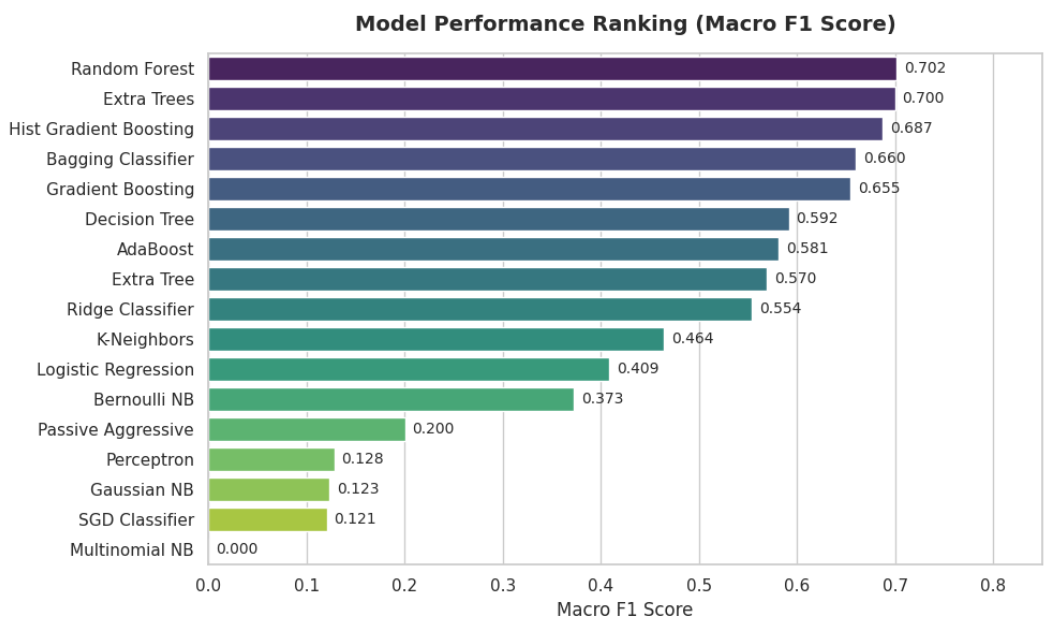

Now loading up with feature engineering based pipeline for ranking